# Home Credit Default Risk (GCI): credit-default prediction, final submission notebook

**Goal.** Predict the probability that a loan applicant will have repayment difficulties (`target = 1`, about 8% of train). **Metric: ROC AUC**, so the submission contains probabilities, not 0/1 labels.

**Data.** Only the two provided files, `train.csv` (171,202 rows, 34 columns including `target`) and `test.csv` (61,500 rows, 33 columns). No external data is read at any point.

**What this notebook contains** (everything runs top to bottom and writes `submission.csv`):

| Part | Content |
|---|---|
| 1 | Setup, configuration and reproducibility |
| 2 | Data loading and cleaning |
| 3 | Feature engineering: base features, ML imputation of `ext_source_*`, loan-term and loan-pricing features, term-context features |
| 4 | Validation scheme and leakage-safe target encoding |
| 5 | LightGBM (5 seeds x 5 folds) |
| 6 | CatBoost with native categorical features (5 seeds x 5 folds) |
| 7 | Blend and out-of-fold evaluation (AUC, calibration, lift) |
| 8 | Final models trained on 100% of the training data and the submission file |
| 9 | Feature importance |
| 10 | Reproducibility and limitations |
| 11 | References |
| 12 | Saving this notebook as a ZIP file |

The exploratory data analysis lives in a companion notebook, **`gci-eda-en.ipynb`**. It reads only `train.csv` and `test.csv` and trains no model for the submission.

**Final model.** A logit-space blend, `0.6 x LightGBM + 0.4 x CatBoost`, both trained on the same label-free feature set (plus out-of-fold target encodings computed inside every training fold).

**Measured performance.** The notebook prints the 5-fold out-of-fold ROC AUC in Part 7. In the development runs that led to this notebook the blend scored about **0.767 to 0.768** in 5-fold CV, and an earlier version of the same pipeline (before the loan-pricing features of section 3.3) scored 0.77 on the public leaderboard, consistent with its CV of 0.7671. Treat any single digit beyond the third decimal as noise: the fold-to-fold standard deviation is about 0.003.

## 0. Competition rules and how this notebook complies

| Rule | How it is satisfied here |
|---|---|
| **No external data** | The only inputs are `train.csv` and `test.csv`. Nothing else is downloaded or read (no bureau tables, no pre-trained models, no web data). The meaning of each column comes from the public Home Credit column documentation, which is *documentation*, not data. |
| **No hand-labeling** | Every prediction comes from the trained models. There are no manual overrides, no rule-based edits to individual test rows and no thresholds applied by hand. The one data-cleaning rule (`days_employed == 365243` is a missing-value code, shown by the companion EDA notebook to be a "no employment record" marker) is applied identically to train and test by code. |
| **Reproducibility** | A single `SEED = 42` drives all random steps: fold splits, inner target-encoding folds, LightGBM seeds `(42, 7, 2024, 11, 99)`, CatBoost seeds `(42, ..., 46)`, k-fold imputation. `PYTHONHASHSEED`, `random` and `numpy` are seeded, and LightGBM runs with `deterministic=True`. Library versions are printed in section 1. As the rules note, bit-identical results across different library versions or hardware cannot be guaranteed. |
| **Private sharing** | Not applicable (no information was obtained privately). |
| **Citing sources** | Section 11 lists every method and library this work builds on. No code was copied from another participant's notebook. |

**Label-free statistics computed on train + test features.** Several features (the ML imputation of `ext_source_*`, group z-scores, quantile bins, value counts) are computed on the concatenation of the train and test *feature* columns. This is transductive but uses no test label (there is none) and no external data. It is stated here openly so a reviewer can judge it. Every statistic that uses the **label** (target encodings) is computed strictly inside the training part of each fold.

## 1. Setup, configuration and reproducibility

All switches are in the next cell. `DEBUG_FAST = True` shrinks the data and the number of trees so the whole notebook can be smoke-tested in a couple of minutes; it must be `False` for the real run.

Expected run time of the full notebook on a Kaggle CPU session: LightGBM 5 seeds x 5 folds about 15 minutes, CatBoost 5 seeds x 5 folds about 2 hours (the dominant cost), final refit on 100% of the data about 15 to 25 minutes.

In [1]:
# ---- imports ----
import os, sys, time, random, warnings, platform, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import lightgbm as lgb
import catboost
from catboost import CatBoostClassifier
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score, log_loss, roc_curve
from sklearn.model_selection import StratifiedKFold, KFold
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

# ---- configuration ----
SEED = 42
N_FOLDS = 5
DEBUG_FAST = False            # True: tiny, fast smoke test of the whole notebook (20k rows, few trees). Keep False for the real run.
LGB_SEEDS = (42, 7, 2024, 11, 99)         # LightGBM: 5 seeds per fold
CAT_SEEDS = (42, 43, 44, 45, 46)          # CatBoost: 5 seeds per fold
BLEND_W_LGB = 0.6                         # blend = 0.6 * LightGBM + 0.4 * CatBoost, in logit space
REFIT_SCALE = 1.1                         # trees for the 100%-data refit = mean best iteration in CV x this factor
LGB_DETERMINISTIC = True                  # LightGBM deterministic mode (stable results for the same data, params and seeds)

# ---- reproducibility ----
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# ---- paths ----
# Data is searched in this order: Kaggle dataset, ./input (course "competition" folder layout, also Colab/Drive after %cd), current folder.
# To use Google Colab: mount Drive, %cd into the "competition" folder, then run this notebook unchanged.
DATA_CANDIDATES = ["/kaggle/input/datasets/kiethe/homecredit-gci", "/kaggle/input/homecredit-gci", "input", "."]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(f"{p}/train.csv") and os.path.exists(f"{p}/test.csv")), None)
assert DATA_PATH is not None, "train.csv / test.csv not found: set DATA_PATH to the folder that contains them"
OUT_PATH = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
OUT_DIR = f"{OUT_PATH}/output"                       # the course tutorial writes output/submission.csv
os.makedirs(OUT_DIR, exist_ok=True)
ID_COL, TARGET = "customer_loan_id", "target"
RENAME_MAP = {"sk_id_curr": "customer_loan_id", "amt_income_total": "income",
              "amt_credit": "credit_amount", "amt_annuity": "annuity"}

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lgb.__version__, "| catboost", catboost.__version__, "| scipy", scipy.__version__)
print("platform:", platform.platform(), "| cpu count:", os.cpu_count())
print("data path:", DATA_PATH, "| output folder:", OUT_DIR, "| DEBUG_FAST =", DEBUG_FAST)

python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scikit-learn 1.6.1 | lightgbm 4.6.0 | catboost 1.2.10 | scipy 1.16.3
platform: Linux-6.18.55+-x86_64-with-glibc2.39 | cpu count: 4
data path: /kaggle/input/datasets/kiethe/homecredit-gci | output folder: /kaggle/working/output | DEBUG_FAST = False


## 2. Data loading and cleaning

Column names are lower-cased and four columns are renamed (`income`, `credit_amount`, `annuity`, `customer_loan_id`). Two data-quality facts matter for the model:

* `days_employed == 365243` is not a real duration: it is a code used for applicants without an employment record (pensioners, unemployed). It is turned into a missing value (the companion EDA notebook checks this against income type, age and organization).
* The loan columns (`credit_amount`, `annuity`, `amt_goods_price`) contain no missing values that need special treatment, but `credit_amount / annuity` can be undefined when `annuity` is 0, so every division in the notebook is a "safe division" that returns NaN instead of infinity.

In [2]:
def load(name):
    df = pd.read_csv(f"{DATA_PATH}/{name}.csv")
    df.columns = df.columns.str.lower()
    return df.rename(columns=RENAME_MAP)


train, test = load("train"), load("test")
if DEBUG_FAST:                                   # smoke-test mode only
    train = train.sample(20_000, random_state=SEED).reset_index(drop=True)
    test = test.head(5_000).reset_index(drop=True)

y = train[TARGET].astype(int).to_numpy()
n_tr = len(train)

# basic integrity checks
assert TARGET in train.columns and TARGET not in test.columns
assert train[ID_COL].is_unique and test[ID_COL].is_unique, "duplicate IDs"
assert not set(train[ID_COL]) & set(test[ID_COL]), "train/test ID overlap"
assert [c for c in train.columns if c != TARGET] == list(test.columns), "train and test columns differ"
print(f"train: {train.shape} | test: {test.shape} | default rate: {y.mean():.2%}")

train: (171202, 34) | test: (61500, 33) | default rate: 8.07%


## 3. Feature engineering

Every feature is a function of the applicant's own row (or of label-free group statistics) and has a credit-risk rationale. Target encodings, which do use the label, are built later inside each fold (section 4).

### 3.1 Base features (70 columns)

| Group | Examples | Why |
|---|---|---|
| Raw numeric | income, credit, annuity, goods price, children, region rating, 4 bureau-inquiry counts | the application itself |
| Time | age, years employed, years since registration, ID issue and phone change (days converted to years) | stability of the applicant's life |
| Categorical | gender, income type, family status, housing, occupation, organization, education, contract type | label-encoded; education kept as an ordered scale |
| Affordability ratios | credit/income, annuity/income, credit/annuity (= nominal term), credit/goods, income per family member | repayment burden |
| `ext_source_*` aggregates | mean, min, max, std, weighted mean, geometric / harmonic / log / logit means, range, coefficient of variation, products with finance variables | `ext_source_1/2/3` are normalized external credit scores and are the strongest signals in the data |
| Age and document timing | employment share of life, age at ID issue, age at registration, sum of change dates | stability and consistency of the profile |

All `ext_source` aggregates that need all three scores are computed only where all three are present, so a missing score is never confused with a low score.

In [3]:
EXT = ["ext_source_1", "ext_source_2", "ext_source_3"]
BUREAU = ["amt_req_credit_bureau_hour", "amt_req_credit_bureau_mon", "amt_req_credit_bureau_qrt", "amt_req_credit_bureau_year"]
EDU_ORDER = ["Lower secondary", "Secondary / secondary special", "Incomplete higher", "Higher education", "Academic degree"]
CAT_LABEL = ["name_contract_type", "code_gender", "name_income_type", "name_family_status", "name_housing_type",
             "occupation_type", "organization_type"]
RAW_NUM = ["cnt_children", "income", "credit_amount", "annuity", "amt_goods_price", "region_population_relative", "own_car_age",
           "flag_work_phone", "cnt_fam_members", "region_rating_client"] + BUREAU
TIME = ["age_years", "years_employed", "years_registration", "years_id_publish", "years_last_phone_change"]
CATS = CAT_LABEL + ["name_education_type"]
FE_EXT = EXT + ["ext_mean", "ext_min", "ext_max", "ext_std", "ext_weighted", "ext2_anchored_mean", "ext_prod_13", "ext_prod_23",
                "ext_mean_x_housing_rent", "ext_mean_x_gender_M", "ext_mean_x_education_low",
                "prod_ext_mean_log_income", "prod_ext_mean_credit_term", "income_ext_mean_ratio", "annuity_ext3_ratio",
                "ltv_x_ext_mean", "composite_risk", "age_x_employed_x_ext",
                "ext_geometric_mean", "ext_harmonic_mean", "ext_log_mean", "ext_logit_mean", "ext_range", "ext_cv"]
FE_OTHER = ["credit_term", "goods_credit_ratio", "annuity_goods_ratio", "credit_income_ratio", "annuity_income_ratio",
            "credit_goods_diff", "income_per_person", "employed_age_ratio", "id_issue_age", "id_publish_age",
            "registration_age", "details_change_sum", "credit_term_x_age", "car_age_ratio", "region_rating_income",
            "total_bureau_req"]
BASE_FEATURES = RAW_NUM + TIME + CATS + FE_EXT + FE_OTHER

# integer codes of categorical columns; used for target encoding (LightGBM) and as native categoricals (CatBoost)
TE_CORE = ["c_occupation", "c_organization"]
TE_EXTRA = ["c_income_type", "c_family", "c_housing", "c_education", "c_occ_gender", "c_edu_gender", "c_edu_income", "c_org_gender"]


def sdiv(a, b):
    # safe division: a zero denominator gives NaN instead of infinity
    return a / b.replace(0, np.nan)


def make_features(df):
    d = df.copy()

    # --- 1. time columns (days before application -> positive years) ---
    d["days_employed"] = d["days_employed"].replace(365243, np.nan)         # 365243 = "no employment record" code
    d["age_years"] = -d["days_birth"] / 365.0
    d["years_employed"] = -d["days_employed"] / 365.0
    d["years_registration"] = -d["days_registration"] / 365.0
    d["years_id_publish"] = -d["days_id_publish"] / 365.0
    d["years_last_phone_change"] = -d["days_last_phone_change"] / 365.0

    # --- 2. categorical columns -> integer codes (same mapping for train and test because they are concatenated first) ---
    is_male = (d["code_gender"] == "M").astype(float)
    is_rent = (d["name_housing_type"] == "Rented apartment").astype(float)
    edu_ord = d["name_education_type"].map({v: i for i, v in enumerate(EDU_ORDER)})
    codes = {c: pd.factorize(d[c].fillna("Unknown"), sort=True)[0] for c in CAT_LABEL}
    edu_code = pd.factorize(d["name_education_type"].fillna("Unknown"), sort=True)[0]

    def pair(a, b):
        v = pd.Series(a, index=d.index).astype(str) + "_" + pd.Series(b, index=d.index).astype(str)
        return pd.factorize(v, sort=True)[0]

    d["c_occupation"], d["c_organization"] = codes["occupation_type"], codes["organization_type"]
    d["c_income_type"], d["c_family"], d["c_housing"] = codes["name_income_type"], codes["name_family_status"], codes["name_housing_type"]
    d["c_education"] = edu_code
    d["c_occ_gender"] = pair(codes["occupation_type"], codes["code_gender"])
    d["c_edu_gender"] = pair(edu_code, codes["code_gender"])
    d["c_edu_income"] = pair(edu_code, codes["name_income_type"])
    d["c_org_gender"] = pair(codes["organization_type"], codes["code_gender"])
    for c in CAT_LABEL:
        d[c] = codes[c]
    d["name_education_type"] = edu_ord                                          # education kept as an ordered scale

    # --- 3. ext_source basics ---
    e1, e2, e3 = (d[c] for c in EXT)
    ext = d[EXT]
    d["ext_mean"], d["ext_min"], d["ext_max"], d["ext_std"] = ext.mean(axis=1), ext.min(axis=1), ext.max(axis=1), ext.std(axis=1)
    w = pd.Series([1.0, 2.0, 1.0], index=EXT)                                   # ext_source_2 gets double weight
    d["ext_weighted"] = ext.mul(w).sum(axis=1, min_count=1) / ext.notna().mul(w).sum(axis=1).replace(0, np.nan)
    e2_anchor = e2.fillna(d["ext_mean"])                                        # anchor on ext_source_2, fall back to the mean
    d["ext2_anchored_mean"] = (2.0 * e2_anchor + e1.fillna(e2_anchor) + e3.fillna(e2_anchor)) / 4.0
    d["ext_prod_13"], d["ext_prod_23"] = e1 * e3, e2 * e3

    # --- 4. aggregates that require all three scores (never mistake a missing score for a low one) ---
    all_ext = ext.notna().all(axis=1)
    ext_c = ext.where(all_ext, axis=0)
    d["ext_geometric_mean"] = ext_c.clip(lower=0).prod(axis=1, min_count=3).pow(1.0 / 3.0)
    ext_zero = ext_c.eq(0).any(axis=1)
    recip = (1.0 / ext_c.where(ext_c != 0)).sum(axis=1, min_count=3)
    d["ext_harmonic_mean"] = 3.0 / recip.replace(0, np.nan)
    d.loc[all_ext & ext_zero, "ext_harmonic_mean"] = 0.0
    d["ext_log_mean"] = np.log1p(ext_c.clip(lower=0)).mean(axis=1)
    eps = 1e-6
    ec = ext_c.clip(lower=eps, upper=1.0 - eps)
    d["ext_logit_mean"] = np.log(ec / (1.0 - ec)).mean(axis=1)
    d["ext_range"] = ext_c.max(axis=1) - ext_c.min(axis=1)
    d["ext_cv"] = d["ext_std"] / d["ext_mean"].where(d["ext_mean"] > 1e-6)

    # --- 5. ext_source x customer group ---
    d["ext_mean_x_housing_rent"] = d["ext_mean"] * is_rent
    d["ext_mean_x_gender_M"] = d["ext_mean"] * is_male
    d["ext_mean_x_education_low"] = d["ext_mean"] * (edu_ord <= 1).astype(float).where(edu_ord.notna())

    # --- 6. affordability ratios ---
    d["credit_term"] = sdiv(d["credit_amount"], d["annuity"])                  # nominal number of payments (ignores interest)
    d["goods_credit_ratio"] = sdiv(d["amt_goods_price"], d["credit_amount"])
    d["annuity_goods_ratio"] = sdiv(d["annuity"], d["amt_goods_price"])
    d["credit_income_ratio"] = sdiv(d["credit_amount"], d["income"])
    d["annuity_income_ratio"] = sdiv(d["annuity"], d["income"])
    d["credit_goods_diff"] = d["credit_amount"] - d["amt_goods_price"]
    d["income_per_person"] = sdiv(d["income"], d["cnt_fam_members"])

    # --- 7. ext_source x finance ---
    log_income = np.log1p(d["income"].where(d["income"] >= 0))
    d["prod_ext_mean_log_income"] = d["ext_mean"] * log_income
    d["prod_ext_mean_credit_term"] = d["ext_mean"] * d["credit_term"]
    d["income_ext_mean_ratio"] = sdiv(d["income"], d["ext_mean"])
    d["annuity_ext3_ratio"] = sdiv(d["annuity"], e3)
    ltv = sdiv(d["credit_amount"], d["amt_goods_price"])
    d["ltv_x_ext_mean"] = ltv * d["ext_mean"]
    dscr = sdiv(d["income"], d["annuity"])
    d["composite_risk"] = (1.0 / dscr.clip(lower=0.1)) * (1.0 - d["ext_mean"].fillna(0.5)) * ltv.fillna(1.0)

    # --- 8. age, employment and documents ---
    d["employed_age_ratio"] = sdiv(d["years_employed"], d["age_years"])
    d["id_issue_age"] = d["age_years"] - d["years_id_publish"]                  # age when the ID was issued
    d["id_publish_age"] = d["years_id_publish"]
    d["registration_age"] = d["age_years"] - d["years_registration"]            # age when the address was registered
    d["details_change_sum"] = d[["years_last_phone_change", "years_registration", "years_id_publish"]].sum(axis=1, min_count=1)
    d["credit_term_x_age"] = d["credit_term"] * d["age_years"]
    d["age_x_employed_x_ext"] = d["age_years"] * d["years_employed"] * d["ext_mean"]   # missing employment stays missing
    d["car_age_ratio"] = sdiv(d["own_car_age"], d["age_years"])
    d["region_rating_income"] = d["region_rating_client"] * log_income
    d["total_bureau_req"] = d[BUREAU].sum(axis=1, min_count=1)

    keep = BASE_FEATURES + TE_CORE + TE_EXTRA
    return d[keep].replace([np.inf, -np.inf], np.nan).astype("float32")


FULL = make_features(pd.concat([train.drop(columns=TARGET), test], ignore_index=True))      # train rows first, then test rows
print(f"base features: {len(BASE_FEATURES)} | columns returned: {FULL.shape[1]} | rows: {FULL.shape[0]:,}")
print("\nMost-missing base features (%):")
print((FULL[BASE_FEATURES].isna().mean() * 100).sort_values(ascending=False).head(8).round(1).to_string())

base features: 70 | columns returned: 80 | rows: 232,702

Most-missing base features (%):
ext_geometric_mean    78.9
ext_log_mean          78.9
ext_harmonic_mean     78.9
ext_logit_mean        78.9
ext_range             78.9
ext_prod_13           78.9
ext_source_1          69.5
own_car_age           66.1


### 3.2 Machine-learning imputation of `ext_source_1/2/3`

`ext_source_1` is missing for about 70% of applicants, `ext_source_3` for about 32%, `ext_source_2` for 0.2%. A tree model can read "missing" directly, but these three scores are the strongest signals, so reconstructing them from the other columns is worth testing.

**Method.** For each score, a LightGBM regressor is trained on the rows where it is observed, using the base features (without the other ext aggregates) plus the *other two* raw scores, and predicts the missing rows. Observed values are never changed and predictions are clipped to [0, 1]. No label is used.

**How good is it?** A separate audit that hid 10% of the observed values and re-imputed them gave R^2 about 0.5 for `ext_source_1` (correlation 0.7), about 0.25 for `ext_source_2` and about 0.13 for `ext_source_3`. So `ext_source_1` is reconstructed reasonably, while `ext_source_3` mostly carries the information of the other columns. Even so, the imputed `ext_source_1` and `ext_source_3` improved cross-validated AUC in development (+0.0016 for the imputation block). The raw columns are kept, so the model still sees the original missing pattern.

In [4]:
BASE_PRED = list(dict.fromkeys(RAW_NUM + TIME + CATS + FE_OTHER))        # inputs for the imputers


def impute_ext_ml(F, pred_cols, seed=SEED):
    out = {}
    for c in EXT:
        cols = list(dict.fromkeys(pred_cols + [o for o in EXT if o != c]))
        observed = F[c].notna().to_numpy()
        missing = ~observed
        model = lgb.LGBMRegressor(objective="regression", n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=seed, n_jobs=-1, verbosity=-1)
        model.fit(F.loc[observed, cols], F.loc[observed, c])
        values = F[c].to_numpy(dtype=float, copy=True)
        if missing.any():
            values[missing] = np.clip(model.predict(F.loc[missing, cols]), 0, 1)
        out[f"{c}_ml"] = values
        print(f"{c}: observed {observed.sum():,} | imputed {missing.sum():,}")
    out["ext_mean_ml"] = np.mean([out[f"{c}_ml"] for c in EXT], axis=0)
    return pd.DataFrame(out, index=F.index).astype("float32")


t0 = time.time()
ML_DF = impute_ext_ml(FULL, BASE_PRED)
ML_COLS = list(ML_DF.columns)
FULL = pd.concat([FULL, ML_DF], axis=1)
print(f"imputation finished in {time.time() - t0:.0f}s | new columns: {ML_COLS}")

ext_source_1: observed 70,862 | imputed 161,840
ext_source_2: observed 232,203 | imputed 499
ext_source_3: observed 158,426 | imputed 74,276
imputation finished in 18s | new columns: ['ext_source_1_ml', 'ext_source_2_ml', 'ext_source_3_ml', 'ext_mean_ml']


### 3.3 Loan-term and loan-pricing features

Two business facts motivate this block.

1. **Nominal term.** `credit_amount / annuity` is the number of payments if the loan carried no interest. Real loans carry interest, so the true term is longer. Rounding the nominal term gives a term bucket (`term_n`), the leftover (`term_frac`) and a crude interest estimate (`interest_total`, `interest_annual`).
2. **Implied interest rate (pricing).** Loan terms are not arbitrary: they sit on a standard grid (6, 12, 18, 24, 30, 36, 48, 60, ... months). Given the credit, the annuity and a candidate term, the monthly rate that makes the annuity repay the credit exactly can be solved numerically (annuity formula). The smallest grid term that is at least the nominal term, and the next one, give two implied annual rates (`p_rate_n1`, `p_rate_n2`). Lenders price loans by risk, so the rate is a **price signal**, and it needs two columns at once (annuity/credit and the term grid), which trees cannot easily reconstruct on their own. Two more columns capture the part of the credit that exceeds the goods price (fees, insurance): `p_fee_gap` (in payments) and `p_fee_ratio`.

In development this block was the only recent addition that passed a two-stage check (screen on one fold split, confirm on a different split): +0.0011 AUC on both, and 5 of 5 folds positive. The grid is an assumption (standard terms), so it is not a certified interest rate; it is a feature.

In [5]:
# ---- (a) nominal-term block ----
tn_round = FULL["credit_term"].round()
TERM_DF = pd.DataFrame({"term_n": tn_round, "term_frac": FULL["credit_term"] - tn_round})
TERM_DF["interest_total"] = (FULL["annuity"] * tn_round / FULL["credit_amount"] - 1).replace([np.inf, -np.inf], np.nan)
TERM_DF["interest_annual"] = (TERM_DF["interest_total"] / (tn_round / 12).replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
TERM_COLS = list(TERM_DF.columns)

# ---- (b) pricing block: implied interest rate on the standard term grid ----
GRID = np.array([6, 12, 18, 24, 30, 36, 48, 60, 72, 84, 96, 120], float)
credit, annuity, goods = (FULL[c].to_numpy(float) for c in ("credit_amount", "annuity", "amt_goods_price"))
with np.errstate(all="ignore"):
    nominal = credit / np.where(annuity == 0, np.nan, annuity)
pos = np.searchsorted(GRID, np.where(np.isnan(nominal), 1e9, nominal), side="left")        # smallest grid term >= nominal term
n1 = np.where(pos < len(GRID), GRID[np.minimum(pos, len(GRID) - 1)], np.nan)
n2 = np.where(pos + 1 < len(GRID), GRID[np.minimum(pos + 1, len(GRID) - 1)], np.nan)


def implied_annual_rate(n):
    # bisection on the monthly rate r in [1e-7, 0.1] such that credit * r / (1 - (1 + r)^-n) == annuity
    with np.errstate(all="ignore"):
        lo, hi = np.full(len(credit), 1e-7), np.full(len(credit), 0.1)
        for _ in range(40):
            mid = (lo + hi) / 2
            too_big = credit * mid / (1 - (1 + mid) ** (-n)) > annuity
            hi, lo = np.where(too_big, mid, hi), np.where(too_big, lo, mid)
        return np.where((annuity * n >= credit) & np.isfinite(n), 12 * (lo + hi) / 2, np.nan)   # annualised; NaN if the term cannot repay the credit


def _ratio(a, b):
    with np.errstate(all="ignore"):
        return a / np.where(b == 0, np.nan, b)


PRICE_DF = pd.DataFrame({"p_n1": n1, "p_rate_n1": implied_annual_rate(n1), "p_rate_n2": implied_annual_rate(n2),
                         "p_gap_n1": n1 - nominal, "p_fee_gap": _ratio(credit - goods, annuity), "p_fee_ratio": _ratio(credit - goods, goods)},
                        index=FULL.index).replace([np.inf, -np.inf], np.nan).astype("float32")
PRICE_COLS = list(PRICE_DF.columns)
print("terms and prices:", TERM_COLS + PRICE_COLS)
print("implied annual rate quartiles:", PRICE_DF["p_rate_n1"].quantile([0.25, 0.5, 0.75]).round(3).to_dict(),
      "| most common grid terms:", pd.Series(n1).value_counts().head(4).to_dict())

terms and prices: ['term_n', 'term_frac', 'interest_total', 'interest_annual', 'p_n1', 'p_rate_n1', 'p_rate_n2', 'p_gap_n1', 'p_fee_gap', 'p_fee_ratio']
implied annual rate quartiles: {0.25: 0.08, 0.5: 0.147, 0.75: 0.247} | most common grid terms: {24.0: 83532, 18.0: 46515, 36.0: 39179, 30.0: 27130}


### 3.4 Term-context features and target-encoding keys

**Why context.** The meaning of an `ext_source` score depends on the kind of loan it is attached to: an `ext_source_2` of 0.5 is average for a short consumer loan and unusual for a very long, large one. For each score the notebook computes its **z-score and percentile inside a peer group of loans with similar term and size** (groups: term decile, term quintile x credit quintile, credit decile). This is `ext_term_ctx`; no label is used. In development it added +0.0013 AUC (5 of 5 folds).

**Keys for target encoding.** Several integer keys combine the term with other variables (term x contract type, term x income type, term x age decile, term x education, term x occupation, half-month term). They are *only* identifiers; the label enters later, inside each fold (section 4).

In [6]:
F_ = FULL


def kc(*arrs):
    # integer code of the tuple of values (a group key)
    s = pd.Series(np.asarray(arrs[0])).astype(str)
    for a in arrs[1:]:
        s = s + "_" + pd.Series(np.asarray(a)).astype(str)
    return pd.factorize(s)[0]


qb = lambda s, q: pd.qcut(pd.Series(np.asarray(s, dtype=float)), q, labels=False, duplicates="drop").to_numpy()


def zin(v, key, min_n=100):
    # z-score of v inside its group; groups with fewer than min_n rows fall back to the global z-score
    d = pd.DataFrame({"v": np.asarray(v, dtype=float), "k": key})
    g = d.groupby("k")["v"]
    cnt, mu, sd = g.transform("count"), g.transform("mean"), g.transform("std")
    ok = (cnt >= min_n) & (sd > 0)
    return np.where(ok, (d["v"] - mu) / sd, (d["v"] - d["v"].mean()) / d["v"].std())


pct = lambda v, key: pd.Series(np.asarray(v, dtype=float)).groupby(key).rank(pct=True).to_numpy()

term, cr, age = F_["credit_term"], F_["credit_amount"], F_["age_years"]
e_m, e2, e3 = F_["ext_mean_ml"], F_["ext_source_2_ml"], F_["ext_source_3_ml"]
tb10, tb5, crb, ageb = qb(term, 10), qb(term, 5), qb(cr, 10), qb(age, 10)
ctx_keys = {"term": kc(tb10), "term_cr": kc(tb5, qb(cr, 5)), "cr": kc(crb)}

CTX_DF = pd.DataFrame({
    **{f"zc_{vn}_{kn}": zin(v, k) for vn, v in (("e", e_m), ("e2", e2), ("e3", e3)) for kn, k in ctx_keys.items()},
    **{f"pc_e_{kn}": pct(e_m, k) for kn, k in ctx_keys.items()}}, index=F_.index)
CTX_COLS = list(CTX_DF.columns)

# integer keys that identify (term bucket, other variable) groups; used by the target encoders in section 4
tn = term.round().clip(0, 120)
KEY_DF = pd.DataFrame({
    "c_term": kc(tn),
    "c_term_ctype": kc(tn, F_["name_contract_type"]),
    "c_term_inc": kc(tn, F_["c_income_type"]),
    "i_term_half": kc((term * 2).round().clip(0, 240)),
    "i_term_age": kc(tn, ageb),
    "i_term_edu": kc(tn, F_["name_education_type"]),
    "i_term_occ": kc(tn, F_["c_occupation"]),
}, index=F_.index)
KEY_COLS = list(KEY_DF.columns)
print(f"context features: {len(CTX_COLS)} | target-encoding keys: {KEY_COLS}")

context features: 12 | target-encoding keys: ['c_term', 'c_term_ctype', 'c_term_inc', 'i_term_half', 'i_term_age', 'i_term_edu', 'i_term_occ']


### 3.5 Assemble the feature matrices

Everything computed so far is label-free and is stored in one matrix for the training rows (`X_all`) and one for the test rows (`X_test_all`). Three feature lists are defined:

* `FEATS_LGB`: numeric features of the LightGBM model (base, ML-imputed ext, term, pricing, term-context).
* `FEATS_CAT`: numeric features of the CatBoost model (the same without the term-context block).
* `CAT_SRC`: ten integer-coded categorical columns that CatBoost treats as **native categorical** features.

In [7]:
ALL_NEW = pd.concat([TERM_DF, PRICE_DF, CTX_DF, KEY_DF], axis=1).replace([np.inf, -np.inf], np.nan).astype("float32")
FULL_ALL = pd.concat([FULL, ALL_NEW], axis=1)
X_all = FULL_ALL.iloc[:n_tr].reset_index(drop=True)
X_test_all = FULL_ALL.iloc[n_tr:].reset_index(drop=True)

FEATS_CAT = list(dict.fromkeys(BASE_FEATURES + ML_COLS + TERM_COLS + PRICE_COLS))
FEATS_LGB = list(dict.fromkeys(FEATS_CAT + CTX_COLS))
CAT_SRC = TE_CORE + TE_EXTRA

# LightGBM configuration: numeric features + out-of-fold target encodings (section 4)
CFG_LGB = dict(
    feats=FEATS_LGB,
    te=TE_CORE + ["c_term", "c_term_ctype", "c_term_inc"],                                                   # smoothed mean-target encodings
    te_resid=["c_term", "c_term_ctype", "c_term_inc", "i_term_half", "i_term_age", "i_term_edu", "i_term_occ"],  # residual encodings (net of ext_source)
)
print(f"X_all {X_all.shape} | X_test_all {X_test_all.shape}")
print(f"LightGBM: {len(FEATS_LGB)} numeric + {len(CFG_LGB['te'])} + {len(CFG_LGB['te_resid'])} target-encoded = "
      f"{len(FEATS_LGB) + len(CFG_LGB['te']) + len(CFG_LGB['te_resid'])} model inputs")
print(f"CatBoost: {len(FEATS_CAT)} numeric + {len(CAT_SRC)} native categorical = {len(FEATS_CAT) + len(CAT_SRC)} model inputs")
assert X_all[FEATS_LGB + CAT_SRC + KEY_COLS].shape[1] > 0 and not X_all[FEATS_LGB].columns.duplicated().any()

X_all (171202, 113) | X_test_all (61500, 113)
LightGBM: 96 numeric + 5 + 7 target-encoded = 108 model inputs
CatBoost: 84 numeric + 10 native categorical = 94 model inputs


## 4. Validation scheme and target encoding

**Validation.** Stratified 5-fold cross-validation (shuffled, seed 42). The same five splits are used for every model, so out-of-fold (OOF) predictions of different models are comparable and can be blended. The metric is ROC AUC, as in the competition. Each fold's validation part is also used for early stopping, so the CV score is very slightly optimistic; the size of this effect is small (thousands of trees are chosen by a plateau of 200 rounds) and it is the same for every model compared.

**Target encoding (the only place the label enters a feature).** A categorical code is replaced by the smoothed default rate of its category: `(sum_y + alpha * global_mean) / (count + alpha)`, `alpha = 20`. To avoid leaking each row's own label:

* training rows get an **inner 5-fold out-of-fold** encoding (a row is encoded with a map built without its own inner fold),
* validation and test rows get the map built on the whole training part of the fold,
* every map is rebuilt inside every fold, so the validation fold never contributes to its own encodings.

**Residual target encoding.** For the term-based keys a second encoding is used: the label minus the default rate expected from `ext_mean_ml` decile, averaged inside each key group (shrinkage `m = 20`). It measures how much a loan-term group is riskier than its `ext_source` level already explains, so it is complementary to the plain encoding rather than a copy of it.

In [8]:
SPLITS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
print("fold sizes:", [len(va) for _, va in SPLITS], "| fold default rates:", [f"{y[va].mean():.4f}" for _, va in SPLITS])


def _smooth_map(keys, yv, gm, alpha=20.0):
    g = pd.DataFrame({"k": np.asarray(keys), "y": np.asarray(yv)})
    g["k"] = g["k"].astype("object").where(g["k"].notna(), "__MISSING__")             # missing is its own group
    st = g.groupby("k", dropna=False)["y"].agg(["sum", "count"])
    return (st["sum"] + alpha * gm) / (st["count"] + alpha)


def target_encode(tr_X, ytr, others, cols, alpha=20.0, inner=5, seed=SEED):
    # smoothed mean-target encoding: inner out-of-fold for the training rows, full-train map for `others` (validation and test)
    ytr = np.asarray(ytr)
    gm = float(ytr.mean())
    te_tr = np.full((len(tr_X), len(cols)), gm, dtype=np.float64)
    for a, b in StratifiedKFold(inner, shuffle=True, random_state=seed).split(tr_X, ytr):
        gm_in = float(ytr[a].mean())
        for j, c in enumerate(cols):
            mp = _smooth_map(tr_X.iloc[a][c].to_numpy(), ytr[a], gm_in, alpha)
            kb = tr_X.iloc[b][c].astype("object").where(tr_X.iloc[b][c].notna(), "__MISSING__")
            te_tr[b, j] = kb.map(mp).fillna(gm_in).to_numpy()
    maps = {c: _smooth_map(tr_X[c].to_numpy(), ytr, gm, alpha) for c in cols}
    enc = []
    for o in others:
        data = {f"{c}_te": o[c].astype("object").where(o[c].notna(), "__MISSING__").map(maps[c]).fillna(gm).to_numpy() for c in cols}
        enc.append(pd.DataFrame(data, index=o.index))
    return pd.DataFrame(te_tr, columns=[f"{c}_te" for c in cols], index=tr_X.index), enc


def te_resid_enc(A, yA, others, cols, ext_col="ext_mean_ml", m=20.0, inner=5, seed=SEED):
    # residual encoding: label minus the rate expected from the ext_source decile, averaged per key group and shrunk by m
    ext = A[ext_col].to_numpy(dtype=float)

    def stats(idx):
        e, yy = ext[idx], yA[idx]
        edges = np.unique(np.nanquantile(e, np.linspace(0.1, 0.9, 9)))
        b = np.digitize(e, edges)
        r = yy - pd.Series(b).map(pd.Series(yy).groupby(b).mean()).to_numpy()
        st = {c: pd.DataFrame({"k": A[c].to_numpy()[idx], "r": r}).groupby("k")["r"].agg(["sum", "count"]) for c in cols}
        return {c: s["sum"] / (s["count"] + m) for c, s in st.items()}

    out = {f"{c}_rte": np.zeros(len(A)) for c in cols}
    for a, b in StratifiedKFold(inner, shuffle=True, random_state=seed).split(A, yA):
        st = stats(a)
        for c in cols:
            out[f"{c}_rte"][b] = pd.Series(A[c].to_numpy()[b]).map(st[c]).fillna(0.0).to_numpy()
    st = stats(np.arange(len(A)))
    oth = [pd.DataFrame({f"{c}_rte": pd.Series(o[c].to_numpy()).map(st[c]).fillna(0.0).to_numpy() for c in cols}) for o in others]
    return pd.DataFrame(out), oth


def fold_data(cfg, tr, va):
    # model matrices for one fold: numeric features + target encodings built from the training rows only
    A, B, T = (X_all.iloc[tr].reset_index(drop=True), X_all.iloc[va].reset_index(drop=True), X_test_all.reset_index(drop=True))
    feats = list(cfg["feats"])
    t_tr, (t_va, t_te) = target_encode(A[cfg["te"]], y[tr], [B[cfg["te"]], T[cfg["te"]]], cfg["te"])
    r_tr, (r_va, r_te) = te_resid_enc(A, y[tr], [B, T], cfg["te_resid"])
    Xtr = pd.concat([A[feats], t_tr, r_tr], axis=1)
    Xva = pd.concat([B[feats], t_va, r_va], axis=1)
    Xte = pd.concat([T[feats], t_te, r_te], axis=1)
    return Xtr, Xva, Xte


# quick leakage sanity check on fold 0: encodings of the training rows must not be (near-)perfect predictors of the label
Xtr0, Xva0, _ = fold_data(CFG_LGB, *SPLITS[0])
te_cols = [c for c in Xtr0.columns if c.endswith(("_te", "_rte"))]
chk = pd.DataFrame({"train AUC (inner OOF)": [roc_auc_score(y[SPLITS[0][0]], Xtr0[c]) for c in te_cols],
                    "validation AUC": [roc_auc_score(y[SPLITS[0][1]], Xva0[c]) for c in te_cols]}, index=te_cols).round(4)
display(chk)
print("A large gap between the two columns would indicate leakage; they should be close.")

fold sizes: [34241, 34241, 34240, 34240, 34240] | fold default rates: ['0.0807', '0.0808', '0.0807', '0.0807', '0.0807']


,train AUC (inner OOF),validation AUC
c_occupation_te,0.5742,0.5741
c_organization_te,0.5696,0.5590
c_term_te,0.6147,0.6140
c_term_ctype_te,0.6302,0.6295
c_term_inc_te,0.6288,0.6257
c_term_rte,0.6027,0.6052
c_term_ctype_rte,0.6196,0.6228
c_term_inc_rte,0.6001,0.6038
i_term_half_rte,0.6358,0.6376
i_term_age_rte,0.5559,0.5499


A large gap between the two columns would indicate leakage; they should be close.


## 5. Model 1: LightGBM

**Why LightGBM.** Gradient-boosted trees are the standard strong baseline for tabular credit data: they handle missing values natively, capture interactions between ratios and scores without manual crossing, and train quickly.

**Configuration (chosen in development, see section 10 for what was tried).** Shallow, heavily regularized trees with a small learning rate: `num_leaves 15`, `max_depth 4`, `min_child_samples 100`, `colsample_bytree 0.4`, `subsample 0.8`, `reg_alpha 5`, `reg_lambda 10`, `learning_rate 0.02`, up to 8000 trees with early stopping (200 rounds) on the validation fold. Five seeds per fold are averaged to reduce variance. The refit step (section 8) re-uses the average best iteration.

Inputs: 96 numeric features + 5 smoothed target encodings + 7 residual target encodings = 108.

In [9]:
LGB_PARAMS = dict(objective="binary", n_estimators=8000, learning_rate=0.02, num_leaves=15, max_depth=4, min_child_samples=100,
                  colsample_bytree=0.4, subsample=0.8, subsample_freq=1, reg_alpha=5.0, reg_lambda=10.0, n_jobs=-1, verbose=-1)
LGB_ES = 200
if LGB_DETERMINISTIC:
    LGB_PARAMS.update(deterministic=True, force_row_wise=True)
if DEBUG_FAST:
    LGB_PARAMS.update(n_estimators=300, learning_rate=0.1)
    LGB_ES, LGB_SEEDS = 30, (SEED,)


def run_lgb_cv(cfg, params, seeds, es_rounds, name="LightGBM"):
    t0 = time.time()
    oof, test_pred, iters, imp = np.zeros(n_tr), np.zeros(len(X_test_all)), [], None
    for k, (tr, va) in enumerate(SPLITS):
        Xtr, Xva, Xte = fold_data(cfg, tr, va)
        imp = pd.Series(0.0, index=Xtr.columns) if imp is None else imp
        for s in seeds:
            m = lgb.LGBMClassifier(**{**params, "random_state": s})
            m.fit(Xtr, y[tr], eval_set=[(Xva, y[va])], eval_metric="auc",
                  callbacks=[lgb.early_stopping(es_rounds, verbose=False), lgb.log_evaluation(0)])
            oof[va] += m.predict_proba(Xva)[:, 1] / len(seeds)
            test_pred += m.predict_proba(Xte)[:, 1] / (len(seeds) * N_FOLDS)
            imp += m.booster_.feature_importance("gain") / (len(seeds) * N_FOLDS)
            iters.append(m.best_iteration_)
        print(f"  fold {k + 1}/{N_FOLDS} done | {time.time() - t0:.0f}s")
    scores = [roc_auc_score(y[va], oof[va]) for _, va in SPLITS]
    print(f"[{name}] AUC = {np.mean(scores):.4f} +- {np.std(scores):.4f} | OOF AUC = {roc_auc_score(y, oof):.4f} | "
          f"log-loss = {log_loss(y, np.clip(oof, 1e-6, 1 - 1e-6)):.5f} | mean trees = {np.mean(iters):.0f} | {time.time() - t0:.0f}s")
    return {"oof": oof, "test_pred": test_pred, "scores": scores, "imp": imp.sort_values(ascending=False), "iters": iters, "seeds": tuple(seeds), "name": name}


res_lgb = run_lgb_cv(CFG_LGB, LGB_PARAMS, LGB_SEEDS, LGB_ES, "LightGBM")
print("per-fold AUC:", np.round(res_lgb["scores"], 4))

  fold 1/5 done | 151s
  fold 2/5 done | 349s
  fold 3/5 done | 517s
  fold 4/5 done | 692s
  fold 5/5 done | 866s
[LightGBM] AUC = 0.7670 +- 0.0027 | OOF AUC = 0.7670 | log-loss = 0.24369 | mean trees = 1384 | 866s
per-fold AUC: [0.7638 0.7677 0.7714 0.7646 0.7676]


## 6. Model 2: CatBoost

**Why a second model.** CatBoost builds symmetric (oblivious) trees and handles categorical features with its own **ordered target statistics**, so its errors differ from LightGBM's and blending them reduces variance. Here the ten integer-coded categorical columns (occupation, organization, income type, family status, housing, education and four pairwise crosses with gender or income type) are passed as native categoricals, so no manual target encoding is used for this model.

**Configuration.** `depth 5`, `l2_leaf_reg 10`, `rsm 0.5` (random feature subset per split), `learning_rate 0.04`, up to 4000 iterations, early stopping after 150 rounds without AUC improvement on the validation fold, 5 seeds per fold. This is the slowest cell of the notebook (about 2 hours without a GPU).

Inputs: 84 numeric features (the LightGBM set without the term-context block) + 10 native categoricals = 94.

In [10]:
CAT_PARAMS = dict(depth=5, l2_leaf_reg=10, rsm=0.5)
CAT_LR, CAT_ITERS, CAT_OD = 0.04, 4000, 150
if DEBUG_FAST:
    CAT_LR, CAT_ITERS, CAT_OD = 0.15, 150, 30

FEATS_C = FEATS_CAT + CAT_SRC
Xc_all = X_all[FEATS_C].copy()
Xc_test = X_test_all[FEATS_C].copy()
for d_ in (Xc_all, Xc_test):
    d_[CAT_SRC] = d_[CAT_SRC].astype("int32")            # CatBoost needs integer (or string) categorical columns


def make_cat(seed, iterations, lr, od_wait=None):
    kw = dict(iterations=iterations, learning_rate=lr, loss_function="Logloss", random_seed=seed, thread_count=-1, verbose=False,
              allow_writing_files=False, cat_features=CAT_SRC, **CAT_PARAMS)
    if od_wait:
        kw.update(eval_metric="AUC", od_type="Iter", od_wait=od_wait)
    return CatBoostClassifier(**kw)


def run_cat_cv(seeds, name="CatBoost"):
    t0 = time.time()
    oof, test_pred, iters = np.zeros(n_tr), np.zeros(len(Xc_test)), []
    for k, (tr, va) in enumerate(SPLITS):
        for s in seeds:
            m = make_cat(s, CAT_ITERS, CAT_LR, CAT_OD)
            m.fit(Xc_all.iloc[tr], y[tr], eval_set=(Xc_all.iloc[va], y[va]), use_best_model=True)
            oof[va] += m.predict_proba(Xc_all.iloc[va])[:, 1] / len(seeds)
            test_pred += m.predict_proba(Xc_test)[:, 1] / (len(seeds) * N_FOLDS)
            iters.append(m.get_best_iteration())
        print(f"  fold {k + 1}/{N_FOLDS} done | {time.time() - t0:.0f}s")
    scores = [roc_auc_score(y[va], oof[va]) for _, va in SPLITS]
    print(f"[{name}] AUC = {np.mean(scores):.4f} +- {np.std(scores):.4f} | OOF AUC = {roc_auc_score(y, oof):.4f} | "
          f"log-loss = {log_loss(y, np.clip(oof, 1e-6, 1 - 1e-6)):.5f} | mean trees = {np.mean(iters):.0f} | {time.time() - t0:.0f}s")
    return {"oof": oof, "test_pred": test_pred, "scores": scores, "iters": iters, "seeds": tuple(seeds), "name": name}


res_cat = run_cat_cv(CAT_SEEDS, "CatBoost")
print("per-fold AUC:", np.round(res_cat["scores"], 4))

  fold 1/5 done | 1230s
  fold 2/5 done | 2510s
  fold 3/5 done | 3677s
  fold 4/5 done | 4712s
  fold 5/5 done | 5769s
[CatBoost] AUC = 0.7672 +- 0.0023 | OOF AUC = 0.7672 | log-loss = 0.24379 | mean trees = 1836 | 5769s
per-fold AUC: [0.7654 0.7672 0.7711 0.7646 0.7678]


## 7. Blend and out-of-fold evaluation

The two models are combined in **logit space**: `p = sigmoid(0.6 * logit(p_lgb) + 0.4 * logit(p_cat))`. Averaging logits (rather than probabilities) keeps the blend a proper ranking combination of two calibrated scores. The weight 0.6 / 0.4 was fixed in development from a coarse grid (0.5 to 0.8); the AUC curve is flat near the optimum, so the exact value matters little. Because AUC only depends on ranking, the final file contains probabilities from this blend and no threshold is applied.

The table, ROC curve, calibration plot and decile lift below use **out-of-fold** predictions only: every applicant is scored by models that never saw that applicant.

,mean fold AUC,std over folds,pooled OOF AUC
LightGBM,0.7670,0.0027,0.7670
CatBoost,0.7672,0.0023,0.7672
Blend 0.6/0.4,0.7682,0.0025,0.7682


correlation of logits (LightGBM vs CatBoost, OOF): 0.9785

Blend weight on LightGBM -> mean fold AUC:
{0.4: 0.7683, 0.5: 0.7683, 0.6: 0.7682, 0.7: 0.768, 0.8: 0.7678}


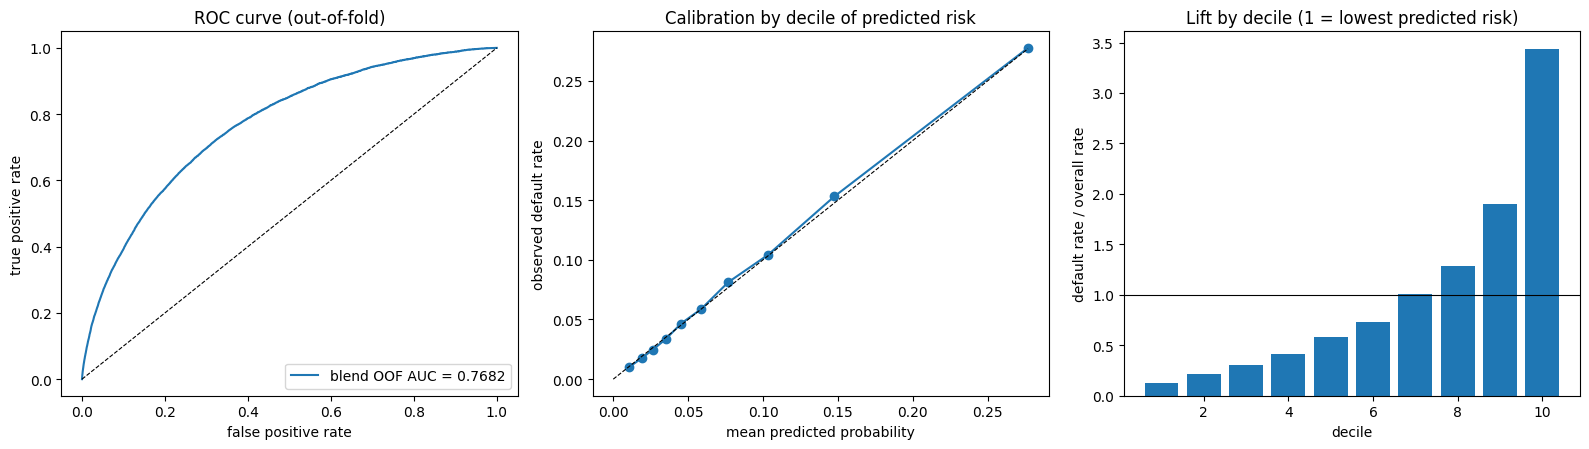

Top decile default rate 27.8% vs bottom decile 1.0% (overall 8.1%).


In [11]:
lg = lambda p: logit(np.clip(p, 1e-6, 1 - 1e-6))
blend = lambda a, b, w=BLEND_W_LGB: expit(w * lg(a) + (1 - w) * lg(b))

oof_blend = blend(res_lgb["oof"], res_cat["oof"])
sc_blend = [roc_auc_score(y[va], oof_blend[va]) for _, va in SPLITS]
summary = pd.DataFrame({
    "LightGBM": [np.mean(res_lgb["scores"]), np.std(res_lgb["scores"]), roc_auc_score(y, res_lgb["oof"])],
    "CatBoost": [np.mean(res_cat["scores"]), np.std(res_cat["scores"]), roc_auc_score(y, res_cat["oof"])],
    "Blend 0.6/0.4": [np.mean(sc_blend), np.std(sc_blend), roc_auc_score(y, oof_blend)]},
    index=["mean fold AUC", "std over folds", "pooled OOF AUC"]).T.round(4)
display(summary)
print("correlation of logits (LightGBM vs CatBoost, OOF):", round(float(np.corrcoef(lg(res_lgb["oof"]), lg(res_cat["oof"]))[0, 1]), 4))

# weight sensitivity (for information only: the weight stays at the value fixed before looking at this notebook's run)
print("\nBlend weight on LightGBM -> mean fold AUC:")
print({w: round(float(np.mean([roc_auc_score(y[va], blend(res_lgb['oof'], res_cat['oof'], w)[va]) for _, va in SPLITS])), 4)
       for w in (0.4, 0.5, 0.6, 0.7, 0.8)})

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
fpr, tpr, _ = roc_curve(y, oof_blend)
ax[0].plot(fpr, tpr, label=f"blend OOF AUC = {roc_auc_score(y, oof_blend):.4f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title="ROC curve (out-of-fold)", xlabel="false positive rate", ylabel="true positive rate")
ax[0].legend(loc="lower right")

q = pd.qcut(oof_blend, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"pred": oof_blend, "obs": y, "q": q}).groupby("q").mean()
ax[1].plot(cal["pred"], cal["obs"], "o-")
ax[1].plot([0, cal["pred"].max()], [0, cal["pred"].max()], "k--", lw=0.8)
ax[1].set(title="Calibration by decile of predicted risk", xlabel="mean predicted probability", ylabel="observed default rate")

ax[2].bar(cal.index + 1, cal["obs"] / y.mean())
ax[2].axhline(1, color="k", lw=0.8)
ax[2].set(title="Lift by decile (1 = lowest predicted risk)", xlabel="decile", ylabel="default rate / overall rate")
plt.tight_layout()
plt.show()
print(f"Top decile default rate {cal['obs'].iloc[-1]:.1%} vs bottom decile {cal['obs'].iloc[0]:.1%} (overall {y.mean():.1%}).")

## 8. Final training on 100% of the data and submission

**Why refit.** Each CV model saw 80% of the training rows. Training on all rows gives slightly more data (+25%), so the number of trees is the mean best iteration found in CV times 1.1. All encodings (target encoding, residual encoding) are rebuilt on the full training set and applied to the test rows exactly as they were applied to validation rows in CV.

**Safety check.** The refit predictions cannot be validated directly (there is no unseen data left), so they are compared with the average of the 25 CV models: if the logit correlation is below 0.98 or the mean prediction differs by more than 10%, the notebook keeps the CV-average predictions instead. Both versions are saved to the `output` folder; the file called `submission.csv` is the one used.

In [12]:
t0 = time.time()
test_cv = blend(res_lgb["test_pred"], res_cat["test_pred"])                      # fallback: average of the CV models

# ---- LightGBM on 100% of the training rows ----
all_idx = np.arange(n_tr)
Xtr_f, _, Xte_f = fold_data(CFG_LGB, all_idx, all_idx[:2000])                    # test encoded with maps built on all training rows
tp_lgb = np.zeros(len(Xte_f))
for si, s in enumerate(res_lgb["seeds"]):
    n = max(10, int(np.mean(res_lgb["iters"][si::len(res_lgb["seeds"])]) * REFIT_SCALE))
    m = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": n, "random_state": s})
    m.fit(Xtr_f, y)
    tp_lgb += m.predict_proba(Xte_f)[:, 1] / len(res_lgb["seeds"])
    print(f"  [refit LightGBM] seed {s}: {n} trees | {time.time() - t0:.0f}s")

# ---- CatBoost on 100% of the training rows ----
tp_cat = np.zeros(len(Xc_test))
for si, s in enumerate(res_cat["seeds"]):
    n = max(10, int(np.mean(res_cat["iters"][si::len(res_cat["seeds"])]) * REFIT_SCALE))
    m = make_cat(s, n, CAT_LR)
    m.fit(Xc_all, y)
    tp_cat += m.predict_proba(Xc_test)[:, 1] / len(res_cat["seeds"])
    print(f"  [refit CatBoost] seed {s}: {n} trees | {time.time() - t0:.0f}s")

test_refit = blend(tp_lgb, tp_cat)
cor = float(np.corrcoef(lg(test_refit), lg(test_cv))[0, 1])
ratio = float(test_refit.mean() / test_cv.mean())
print(f"safety check: logit correlation with CV-average = {cor:.4f} | mean ratio = {ratio:.3f}")
use_refit = cor >= 0.98 and abs(ratio - 1) < 0.10
test_final = test_refit if use_refit else test_cv
print("USING:", "refit on 100% of the training data" if use_refit else "average of the CV models (safety check failed)")

  [refit LightGBM] seed 42: 1454 trees | 32s
  [refit LightGBM] seed 7: 1552 trees | 63s
  [refit LightGBM] seed 2024: 1438 trees | 92s
  [refit LightGBM] seed 11: 1549 trees | 125s
  [refit LightGBM] seed 99: 1618 trees | 159s
  [refit CatBoost] seed 42: 2036 trees | 429s
  [refit CatBoost] seed 43: 1842 trees | 683s
  [refit CatBoost] seed 44: 2091 trees | 962s
  [refit CatBoost] seed 45: 1923 trees | 1218s
  [refit CatBoost] seed 46: 2201 trees | 1514s
safety check: logit correlation with CV-average = 0.9990 | mean ratio = 1.004
USING: refit on 100% of the training data


output/submission.csv written: (61500, 2) | mean prediction 0.0890 (training default rate 0.0807) | min 0.0024 | max 0.8430


,SK_ID_CURR,TARGET
0,171202,0.029256
1,171203,0.290808
2,171204,0.157692
3,171205,0.097991
4,171206,0.208120


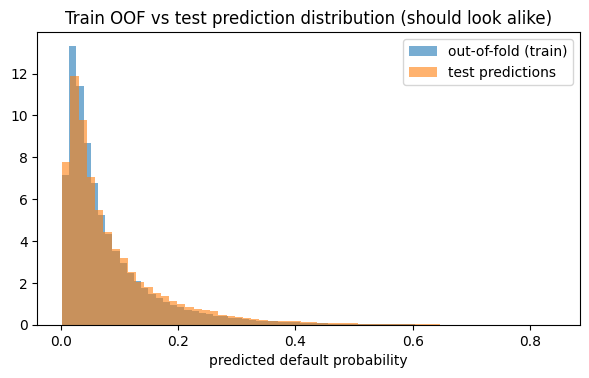

In [13]:
sample_path = f"{DATA_PATH}/sample_submission.csv"
if os.path.exists(sample_path):
    sample = pd.read_csv(sample_path)
    id_name, target_name = sample.columns[0], sample.columns[1]
else:
    id_name, target_name = "SK_ID_CURR", "TARGET"

submission = pd.DataFrame({id_name: test[ID_COL].to_numpy(), target_name: test_final})
submission.to_csv(f"{OUT_DIR}/submission.csv", index=False)
pd.DataFrame({id_name: test[ID_COL].to_numpy(), target_name: test_cv}).to_csv(f"{OUT_DIR}/submission_cv_average.csv", index=False)

# ---- format checks ----
chk_sub = pd.read_csv(f"{OUT_DIR}/submission.csv")
assert len(chk_sub) == len(test) and chk_sub[id_name].is_unique, "wrong number of rows or duplicate IDs"
assert (chk_sub[id_name].to_numpy() == test[ID_COL].to_numpy()).all(), "IDs not in test order"
assert chk_sub[target_name].notna().all() and chk_sub[target_name].between(0, 1).all(), "invalid probabilities"
if os.path.exists(sample_path):
    assert list(chk_sub.columns) == list(sample.columns) and set(chk_sub[id_name]) == set(sample[id_name]), "does not match sample_submission.csv"
print(f"output/submission.csv written: {chk_sub.shape} | mean prediction {chk_sub[target_name].mean():.4f} "
      f"(training default rate {y.mean():.4f}) | min {chk_sub[target_name].min():.4f} | max {chk_sub[target_name].max():.4f}")
display(chk_sub.head())

plt.figure(figsize=(7, 3.8))
plt.hist(oof_blend, bins=60, alpha=0.6, density=True, label="out-of-fold (train)")
plt.hist(test_final, bins=60, alpha=0.6, density=True, label="test predictions")
plt.xlabel("predicted default probability")
plt.legend()
plt.title("Train OOF vs test prediction distribution (should look alike)")
plt.show()

## 9. Feature importance

LightGBM gain importance (average over folds and seeds). Gain tells how much a feature reduced the loss when it was used for splitting; it describes the model, not a causal effect. Correlated features share credit, so a single bar understates the importance of the whole group (for example the many `ext_source` variants).

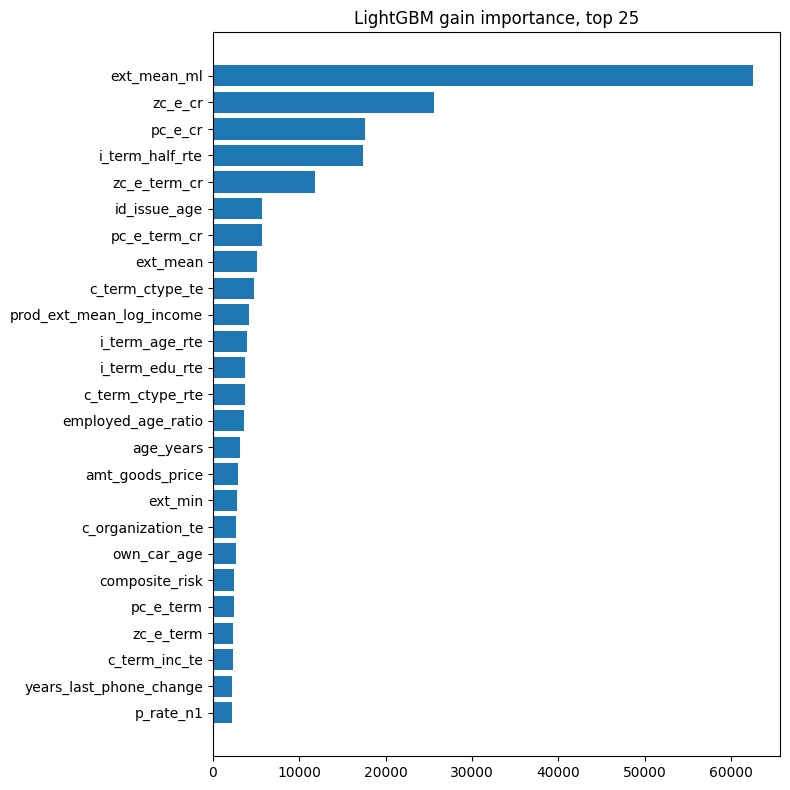

,"share of total gain, %"
term-context (ext_term_ctx),23.8
ML-imputed ext_source,22.2
other base features,20.8
target encodings,15.4
ext_source aggregates / interactions,12.7
pricing,3.1
term,2.0


In [14]:
imp = res_lgb["imp"]
top = imp.head(25)[::-1]
plt.figure(figsize=(8, 8))
plt.barh(top.index, top.values)
plt.title("LightGBM gain importance, top 25")
plt.tight_layout()
plt.show()

def group_of(c):
    if c.endswith("_rte") or c.endswith("_te"): return "target encodings"
    if c.startswith(("zc_", "pc_")): return "term-context (ext_term_ctx)"
    if c.startswith("p_"): return "pricing"
    if c in TERM_COLS: return "term"
    if c.endswith("_ml"): return "ML-imputed ext_source"
    if c.startswith("ext") or "ext" in c: return "ext_source aggregates / interactions"
    return "other base features"

share = (imp / imp.sum()).groupby(imp.index.map(group_of)).sum().sort_values(ascending=False)
display((share * 100).round(1).rename("share of total gain, %").to_frame())

## 10. Reproducibility, limitations and what was tried

**Reproducibility.** Every random component is seeded: `PYTHONHASHSEED`, Python and NumPy seeds, the CV splitter (42), the inner target-encoding splitters (42), the imputation regressors (42), five LightGBM seeds (42, 7, 2024, 11, 99) and five CatBoost seeds (42 to 46). LightGBM runs with `deterministic=True` and `force_row_wise=True`. Re-running on the same library versions (printed in section 1) and the same number of CPU threads should give the same predictions; across different library versions or machines, small numerical differences (typically in the fourth decimal of the AUC) are possible. No file is read except `train.csv`, `test.csv` and (for the column format only) `sample_submission.csv`.

**Label-free use of the test features.** Three steps compute statistics on train and test features together, never on any label: the ML imputers of `ext_source` (section 3.2), the group z-scores and percentile ranks of the term-context block (section 3.4), and the category codes. This is the usual transductive preprocessing of a tabular competition; it can be removed (fit on train only, apply to test) at the cost of a small change in the features. It does not use any information about test targets.

**Limitations.**

* The CV score is measured on 80% models; the submitted models were refit on 100% and cannot be scored directly (hence the safety check in section 8).
* Early stopping uses the validation fold, so CV is slightly optimistic. The leaderboard is the unbiased check.
* The pricing block assumes a standard term grid; it is a feature, not a certified interest rate.
* The ML imputation of `ext_source_3` is weak (R^2 about 0.13 in the audit); its value comes from combining the information of other columns, not from recovering the true score.
* Gains from the last additions (pricing +0.0009 AUC for LightGBM, term-context +0.0013) are small compared with the fold-to-fold standard deviation (about 0.003) and were accepted only after a paired per-fold test with a confirmation on a different fold split.

**What was tried and is not in this notebook.** Ideas that did not improve cross-validated AUC were removed on purpose, to keep this notebook limited to what is used: additional model families (XGBoost, GAM, neural networks), hyper-parameter re-tuning, pseudo-labelling, denoising auto-encoder features, automatic feature search, and further business-feature blocks (life-stage, peer-group and bureau-ratio features). The imputation of other columns (employment days, car age, bureau counts) also did not help.

**Expected result.** Cross-validated AUC about 0.767 to 0.768 for the blend. An earlier version of this pipeline (without the pricing block) scored 0.77 on the public leaderboard.

## 11. References and sources

All code in this notebook was written for this project. The methods are standard and are cited here. Replace the last two items with your own statement if they do not match your situation.

* Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* NeurIPS. (LightGBM)
* Prokhorenkova, L. et al. (2018). *CatBoost: unbiased boosting with categorical features.* NeurIPS. (CatBoost, ordered target statistics)
* Micci-Barreca, D. (2001). *A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems.* SIGKDD Explorations. (smoothed target encoding)
* Pedregosa, F. et al. (2011). *Scikit-learn: machine learning in Python.* JMLR. (`StratifiedKFold`, `roc_auc_score`)
* Home Credit Default Risk (Kaggle, 2018): description of the application-table columns, including the `EXT_SOURCE_*` scores and the 365243 code for `DAYS_EMPLOYED`. The annuity formula used in the pricing block is the standard fixed-payment loan formula.
* Competition data: `train.csv`, `test.csv`, `sample_submission.csv` supplied by the course organizers (dataset `kiethe/homecredit-gci`); no other data was used.
* Companion notebook: `gci-eda-en.ipynb` (exploratory analysis, which informed the choices in section 3 but produces no model output).
* Reference code from other notebooks: **none was copied.** (Edit this line if you reused anything.)
* AI assistance: this notebook was developed with the help of an AI coding assistant (Claude, Anthropic) under the author's direction; the author reviewed the results. (Edit or remove according to the course policy.)

## 12. Saving this notebook as a ZIP file

The next cell compresses this notebook file into `tutorial.zip` (the name can be changed). If the notebook file cannot be found automatically (it depends on the platform), set `NOTEBOOK_FILE` to its path. Download the ZIP from the output panel and submit it together with the notebook, as the course requires.

In [15]:
NOTEBOOK_FILE = None          # e.g. "/kaggle/working/tutorial.ipynb"; None = detect automatically
ZIP_NAME = "tutorial.zip"

cands = [NOTEBOOK_FILE] if NOTEBOOK_FILE else sorted(glob.glob("*.ipynb") + glob.glob(f"{OUT_PATH}/*.ipynb"), key=os.path.getmtime, reverse=True)
cands = [c for c in cands if c and os.path.exists(c)]
if cands:
    nb_path = cands[0]
    with zipfile.ZipFile(f"{OUT_PATH}/{ZIP_NAME}", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(nb_path, arcname=os.path.basename(nb_path))
    print(f"{nb_path} -> {OUT_PATH}/{ZIP_NAME} ({os.path.getsize(f'{OUT_PATH}/{ZIP_NAME}') / 1024:.0f} KB)")
else:
    print("Notebook file not found on disk (on some platforms it is only saved after the session). "
          "Save it, set NOTEBOOK_FILE above, and run this cell again, or zip it by hand.")

__notebook__.ipynb -> /kaggle/working/tutorial.zip (169 KB)
